# Environment 1: Grid Navigation Minesweeper with Sidewalks
### Deep Q-Learning (DQN) Training, Telemetry Analytics, & Cognitive Schema Evaluation

In this notebook, we train, diagnose, and rigorously analyze our baseline reinforcement learning agent for grid navigation:
- **Grid Layout**: $8 \times 6$ grid (8 columns, 6 rows).
- **Start Position**: Left sidewalk column (`(row 0, col 0)` or dynamic sidewalk start).
- **Goal Zone**: The entire right column (`col 7`, rows 0–5). Reaching any goal cell yields **+100 reward (WIN)**.
- **Sidewalks**: The top edge (`row 0`), bottom edge (`row 5`), and left edge (`col 0`) are guaranteed mine-free safe paths.
- **Mines**: 6 hidden mines in interior cells (`rows 1–4`, `cols 1–6`). Stepping on a mine triggers **-100 penalty (EXPLOSION)**.
- **Base Movement Cost**: Every move costs **-0.5 points** (energy penalty enforcing shortest-path efficiency).
- **Action Space**: **4 pure directional movements (`UP, DOWN, LEFT, RIGHT`)** with automatic tile reveal on entry.

---

### Key Research Questions in Environment 1:
1. **How fast does DQN converge on a structured spatial grid?**
2. **Why does Vanilla Q-Network (online updates, no replay/target net) perform competitively on this simple layout?**
3. **What does the learned Schema (State-Value Field $V(s)$) look like, and how does fog-of-war influence value estimation?**



## 1. Setup & Environment Registration


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch

import environment
from environment.grid_nav_env import (
    GridNavEnv, ACTION_NAMES,
    MOVE_UP, MOVE_DOWN, MOVE_LEFT, MOVE_RIGHT
)
from models.grid_dqn_agent import (
    GridNavDQNAgent, VanillaQNAgent, GridStateEncoder,
    train_dqn_agent, train_qn_agent
)
from notebooks.visualizer import (
    record_episode, record_winning_episode, plot_trajectory,
    draw_grid_state, plot_q_value_heatmap, evaluate_agent_retention,
    run_forgetting_benchmark
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
print("Gymnasium environments registered successfully!")



PyTorch version: 2.10.0+cpu
CUDA Available:  False
Gymnasium environments registered successfully!


## 2. Inspecting Environment 1 Layout
We inspect the state space dimensions, action space, and initial board layout.



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v1 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


Environment Specifications:
  Grid Dimensions:    8 cols x 6 rows
  Number of Mines:    6
  Sidewalks Active:   True
  Max Steps Budget:   96
  Action Space:       Discrete(4) (4 directional moves: UP, DOWN, LEFT, RIGHT)
  Initial Agent Pos:  [0 0]


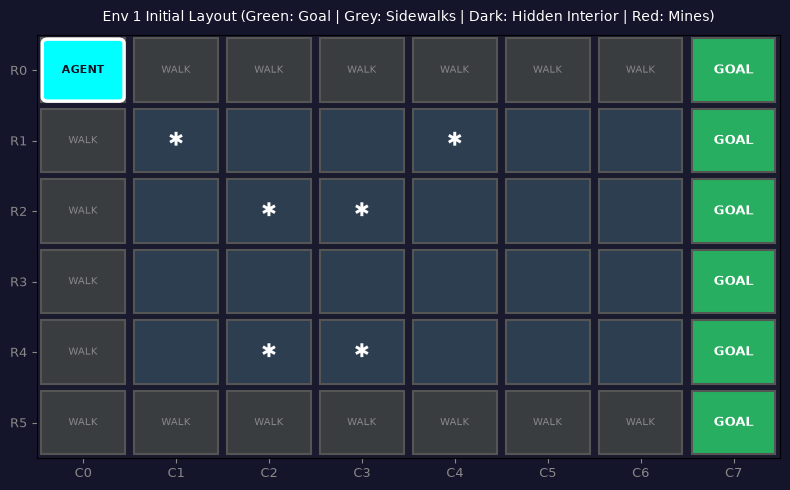

In [2]:
env = gym.make("GridNavMinesweeper-v1", seed=42)
obs, info = env.reset(seed=42)

print("Environment Specifications:")
print(f"  Grid Dimensions:    {env.unwrapped.grid_width} cols x {env.unwrapped.grid_height} rows")
print(f"  Number of Mines:    {env.unwrapped.num_mines}")
print(f"  Sidewalks Active:   {env.unwrapped.sidewalks_on}")
print(f"  Max Steps Budget:   {env.unwrapped.max_steps}")
print(f"  Action Space:       {env.action_space} (4 directional moves: UP, DOWN, LEFT, RIGHT)")
print(f"  Initial Agent Pos:  {obs['agent_pos']}")

# Preview initial board layout
fig, ax = plt.subplots(figsize=(8, 5), facecolor="#14142B")
frame_0 = {
    "board": obs["board"],
    "cell_types": obs["cell_types"],
    "agent_pos": obs["agent_pos"],
    "action_name": "INITIAL STATE",
    "reward": 0.0,
    "event": "ready",
    "step": 0,
    "mine_map": env.unwrapped._mine_map,
}
draw_grid_state(ax, frame_0, show_mines=True)
plt.title("Env 1 Initial Layout (Green: Goal | Grey: Sidewalks | Dark: Hidden Interior | Red: Mines)", 
          color="white", fontsize=10, pad=10)
plt.tight_layout()
plt.show()



## 3. Spatial Perception & Neural Architecture

### 7-Channel Input Representation
The agent does not receive a flat coordinates vector. It perceives the grid as an image-like tensor of shape $(7, H, W)$:
1. `Channel 0`: Agent Position (1.0 at agent coordinates, 0.0 elsewhere)
2. `Channel 1`: Revealed adjacent mine numbers ($0..8 / 8.0$)
3. `Channel 2`: Unrevealed tiles mask
4. `Channel 3`: Flagged tiles mask
5. `Channel 4`: Sidewalk safe path mask
6. `Channel 5`: Goal zone mask (Column 7)
7. `Channel 6`: Normalized steps remaining countdown

### Conv2D Feature Extractor
```python
self.conv = nn.Sequential(
    nn.Conv2d(in_channels=7, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
)
```



## 4. Train the DQN Agent on Environment 1

In [3]:
# ─────────────────────────────────────────────────────────────
# Hyperparameters
# ─────────────────────────────────────────────────────────────
NUM_EPISODES = 2500
SEED = 42

train_env = gym.make("GridNavMinesweeper-v1", seed=SEED)

dqn_agent = GridNavDQNAgent(
    grid_size=(train_env.unwrapped.grid_width, train_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.985,
    batch_size=64,
    target_update_freq=10,
)

dqn_metrics = train_dqn_agent(
    env=train_env,
    agent=dqn_agent,
    num_episodes=NUM_EPISODES,
    update_freq=4,
    warmup_steps=64,
    verbose_freq=100,
)

os.makedirs("checkpoints", exist_ok=True)
dqn_agent.save("checkpoints/env1_dqn.pt", save_buffer=True)
print(f"\nModel weights & memory ({len(dqn_agent.replay_buffer)} transitions) saved to checkpoints/env1_dqn.pt")



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v1 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


Starting DQN Training on GridNavEnv for 2500 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  100 |    +35.0 |      68.0% |      7 |    0.221 |     0.0% |     21.8s


  200 |    +93.9 |      96.0% |      8 |    0.050 |    12.5% |     36.3s


  300 |    +41.8 |      84.0% |     20 |    0.050 |     0.0% |     53.7s


  400 |   +102.1 |     100.0% |      7 |    0.050 |     0.0% |     73.0s


... (18 outputs left out)

 2300 |   +102.5 |     100.0% |      8 |    0.050 |    12.5% |    250.8s


 2400 |    +85.9 |      92.0% |     13 |    0.050 |    15.4% |    259.9s


 2500 |   +102.8 |     100.0% |      7 |    0.050 |     0.0% |    269.3s
═══════════════════════════════════════════════════════════════════════════
Training completed in 269.26s!
First Goal reached at Episode 18!
Final 25-episode win rate: 100.0%



Model weights & memory (20000 transitions) saved to checkpoints/env1_dqn.pt


## 5. Diagnostic Graphs & Performance Telemetry


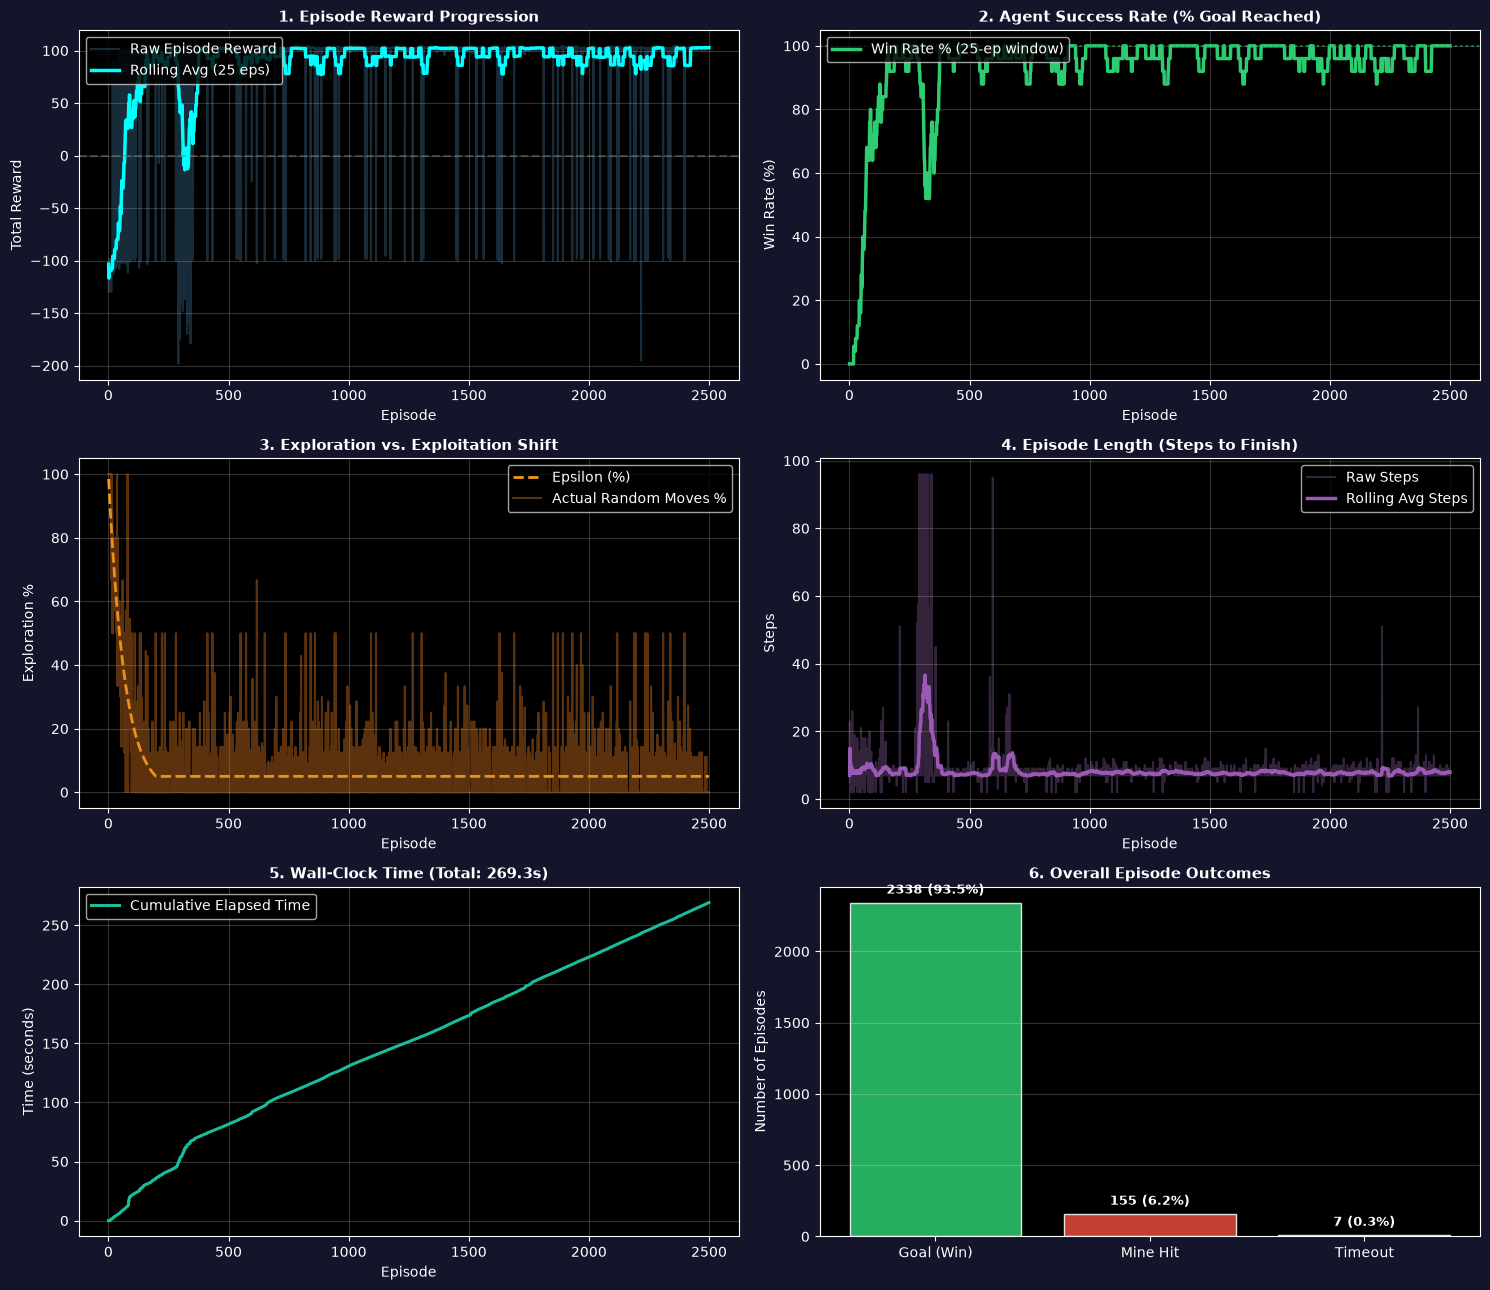

In [4]:
plt.style.use("dark_background")
fig, axes = plt.subplots(3, 2, figsize=(15, 13), facecolor="#14142B")

episodes = dqn_metrics["episodes"]

# ── 1. Episode Rewards & Rolling Average ──
ax = axes[0, 0]
ax.plot(episodes, dqn_metrics["rewards"], color="#5DADE2", alpha=0.25, label="Raw Episode Reward")
ax.plot(episodes, dqn_metrics["rolling_rewards"], color="#00FFFF", linewidth=2.5, label="Rolling Avg (25 eps)")
ax.axhline(0, color="#777777", linestyle="--", alpha=0.5)
ax.set_title("1. Episode Reward Progression", fontsize=11, fontweight="bold", color="white")
ax.set_xlabel("Episode", color="white")
ax.set_ylabel("Total Reward", color="white")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.2)

# ── 2. Success / Win Rate % ──
ax = axes[0, 1]
ax.plot(episodes, dqn_metrics["rolling_win_rate"], color="#2ECC71", linewidth=2.5, label="Win Rate % (25-ep window)")
ax.set_ylim(-5, 105)
ax.axhline(100, color="#27AE60", linestyle=":", alpha=0.7)
ax.set_title("2. Agent Success Rate (% Goal Reached)", fontsize=11, fontweight="bold", color="white")
ax.set_xlabel("Episode", color="white")
ax.set_ylabel("Win Rate (%)", color="white")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.2)

# ── 3. Exploration vs Exploitation Dynamics ──
ax = axes[1, 0]
ax.plot(episodes, [e * 100 for e in dqn_metrics["epsilons"]], color="#F39C12", linewidth=2.0, linestyle="--", label="Epsilon (%)")
ax.plot(episodes, dqn_metrics["exploration_rate"], color="#E67E22", alpha=0.4, label="Actual Random Moves %")
ax.set_title("3. Exploration vs. Exploitation Shift", fontsize=11, fontweight="bold", color="white")
ax.set_xlabel("Episode", color="white")
ax.set_ylabel("Exploration %", color="white")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.2)

# ── 4. Episode Length (Steps taken) ──
ax = axes[1, 1]
ax.plot(episodes, dqn_metrics["steps"], color="#AF7AC5", alpha=0.3, label="Raw Steps")
rolling_steps = [np.mean(dqn_metrics["steps"][max(0, i-25):i+1]) for i in range(len(episodes))]
ax.plot(episodes, rolling_steps, color="#9B59B6", linewidth=2.5, label="Rolling Avg Steps")
ax.set_title("4. Episode Length (Steps to Finish)", fontsize=11, fontweight="bold", color="white")
ax.set_xlabel("Episode", color="white")
ax.set_ylabel("Steps", color="white")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.2)

# ── 5. Training Wall-Clock Time ──
ax = axes[2, 0]
ax.plot(episodes, dqn_metrics["cumulative_time"], color="#1ABC9C", linewidth=2.2, label="Cumulative Elapsed Time")
ax.set_title(f"5. Wall-Clock Time (Total: {dqn_metrics['cumulative_time'][-1]:.1f}s)", fontsize=11, fontweight="bold", color="white")
ax.set_xlabel("Episode", color="white")
ax.set_ylabel("Time (seconds)", color="white")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.2)

# ── 6. Outcome Distribution (3 categories only) ──
ax = axes[2, 1]
total_wins = sum(dqn_metrics["wins"])
total_mine_hits = sum(1 for m in dqn_metrics["mine_hits"] if m > 0)
total_timeouts = sum(dqn_metrics["timeouts"])

categories = ["Goal (Win)", "Mine Hit", "Timeout"]
counts = [total_wins, total_mine_hits, total_timeouts]
colors = ["#2ECC71", "#E74C3C", "#F1C40F"]
bars = ax.bar(categories, counts, color=colors, edgecolor="white", alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + (max(counts)*0.02), f"{yval} ({yval/len(episodes)*100:.1f}%)", 
            ha="center", va="bottom", color="white", fontsize=9, fontweight="bold")
ax.set_title("6. Overall Episode Outcomes", fontsize=11, fontweight="bold", color="white")
ax.set_ylabel("Number of Episodes", color="white")
ax.grid(True, alpha=0.2, axis="y")

plt.tight_layout()
plt.show()



## 6. Trajectory Showcase: Examining Agent Decisions

We plot clean spatial trajectory maps for key scenarios:
1. **Optimal Path to Goal**: Navigating along the sidewalk to Column 7.
2. **Mine Detonation**: Stepping off the sidewalk into the interior hazard zone.
3. **Alternative Sidewalk Start**: Starting at Row 4 along the left sidewalk and reaching the Goal.



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v1 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


Optimal Trajectory (Ep 18) | Steps: 7 | Won: True


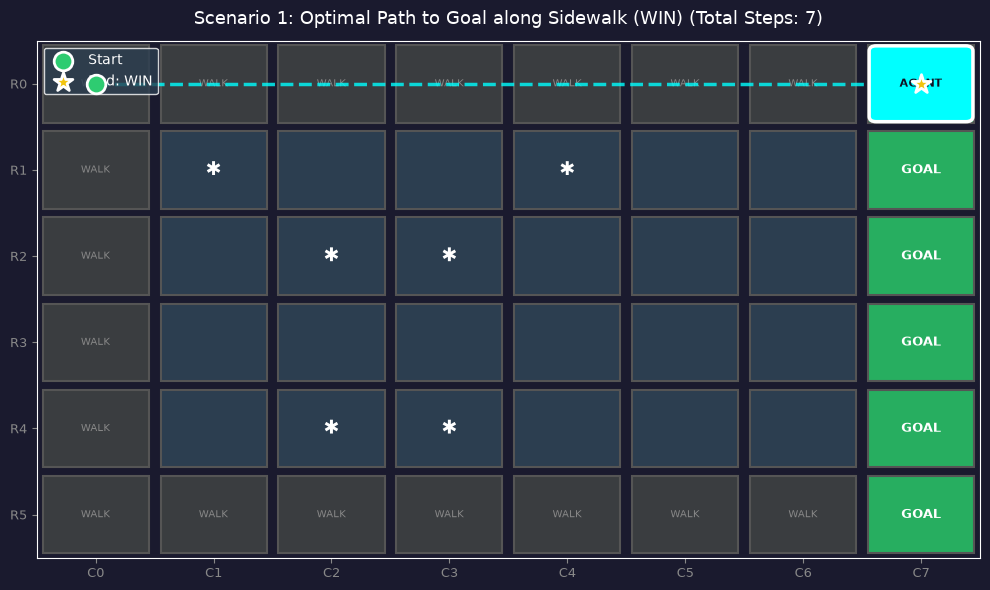

In [5]:
eval_env = gym.make("GridNavMinesweeper-v1", seed=42)

# Scenario 1: Replay the best actual winning episode recorded during training
if dqn_metrics.get("best_winning_history") is not None:
    history_goal = dqn_metrics["best_winning_history"]
    print(f"Optimal Trajectory (Ep {dqn_metrics['first_win_episode']}) | Steps: {len(history_goal)-1} | Won: {history_goal[-1].get('won')}")
else:
    history_goal = record_winning_episode(eval_env, dqn_agent, start_pos=(0, 0))

plot_trajectory(history_goal, title="Scenario 1: Optimal Path to Goal along Sidewalk (WIN)")



Mine Detonation: Steps=2 | Event=mine_hit | Reward=-100.5


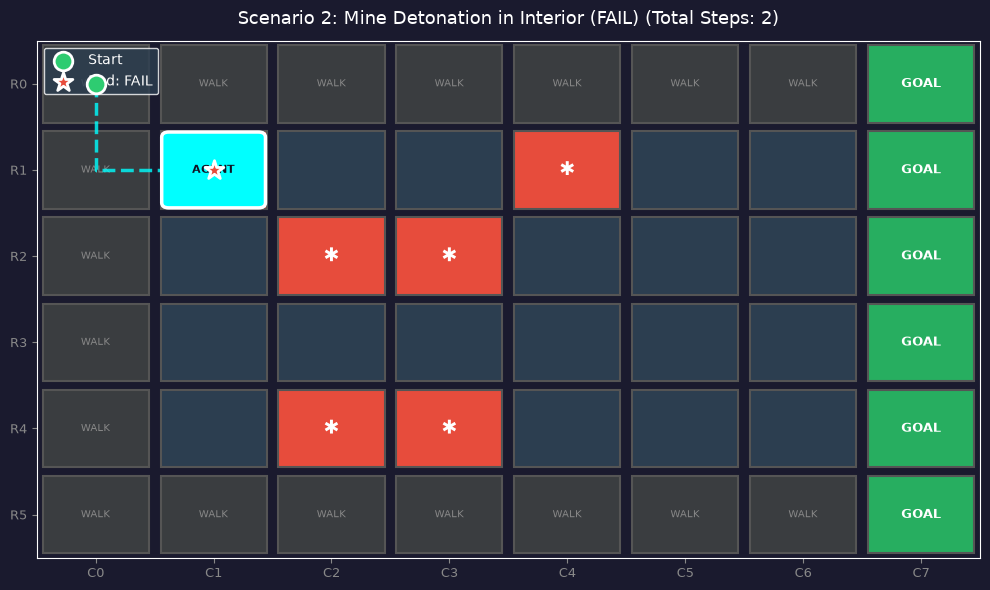

In [6]:
# Scenario 2: Mine Detonation in Interior (Stepping into cell (1,1))
history_mine = record_episode(
    eval_env,
    actions_script=[MOVE_DOWN, MOVE_RIGHT],
    start_pos=(0, 0)
)
print(f"Mine Detonation: Steps={len(history_mine)-1} | Event={history_mine[-1].get('event')} | Reward={history_mine[-1].get('reward')}")
plot_trajectory(history_mine, title="Scenario 2: Mine Detonation in Interior (FAIL)")



Row 4 Sidewalk Start: Steps=8 | Won=True | End Pos=(5, 7)


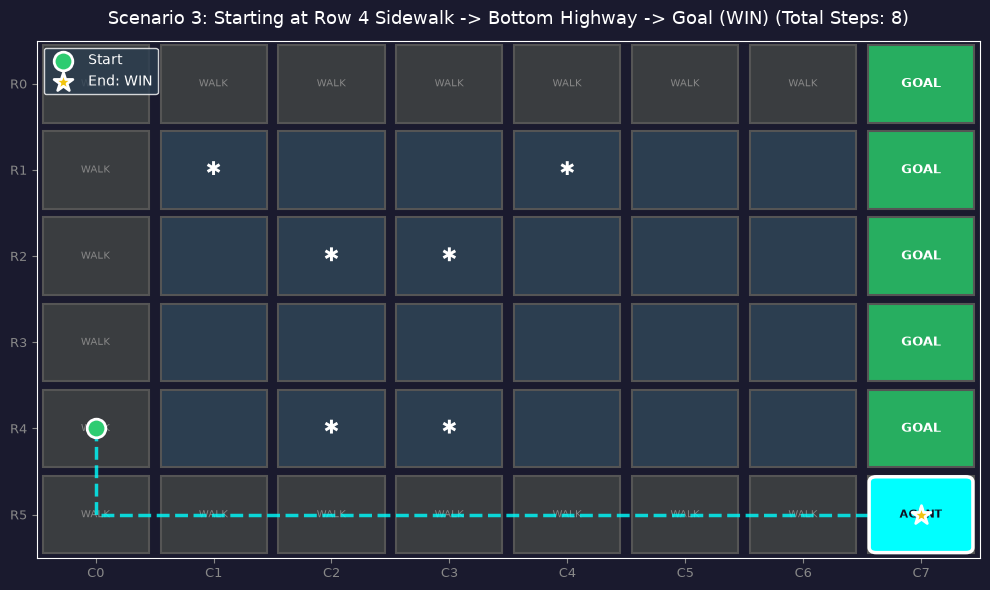

In [7]:
# Scenario 3: Sidewalk Start at Row 4
history_side = record_episode(
    eval_env,
    actions_script=[MOVE_DOWN] + [MOVE_RIGHT] * 7,
    start_pos=(4, 0)
)
print(f"Row 4 Sidewalk Start: Steps={len(history_side)-1} | Won={history_side[-1].get('won')} | End Pos={history_side[-1].get('agent_pos')}")
plot_trajectory(history_side, title="Scenario 3: Starting at Row 4 Sidewalk -> Bottom Highway -> Goal (WIN)")



## 7. Algorithmic Comparison: DQN vs. Vanilla Q-Network (QN)



Starting Vanilla QN (Online) Training for 2500 episodes...


Vanilla QN Ep 100 | Win Rate:  64.0% | Ep Reward: +100.0


Vanilla QN Ep 200 | Win Rate:  84.0% | Ep Reward: +102.5


Vanilla QN Ep 300 | Win Rate:  88.0% | Ep Reward: +102.5


Vanilla QN Ep 400 | Win Rate:  92.0% | Ep Reward: +102.5


Vanilla QN Ep 500 | Win Rate:  92.0% | Ep Reward: +102.5


... (16 outputs left out)

Vanilla QN Ep 2200 | Win Rate:  96.0% | Ep Reward: +102.5


Vanilla QN Ep 2300 | Win Rate:  96.0% | Ep Reward: +102.5


Vanilla QN Ep 2400 | Win Rate:  92.0% | Ep Reward: +102.5


Vanilla QN Ep 2500 | Win Rate:  96.0% | Ep Reward: +103.0


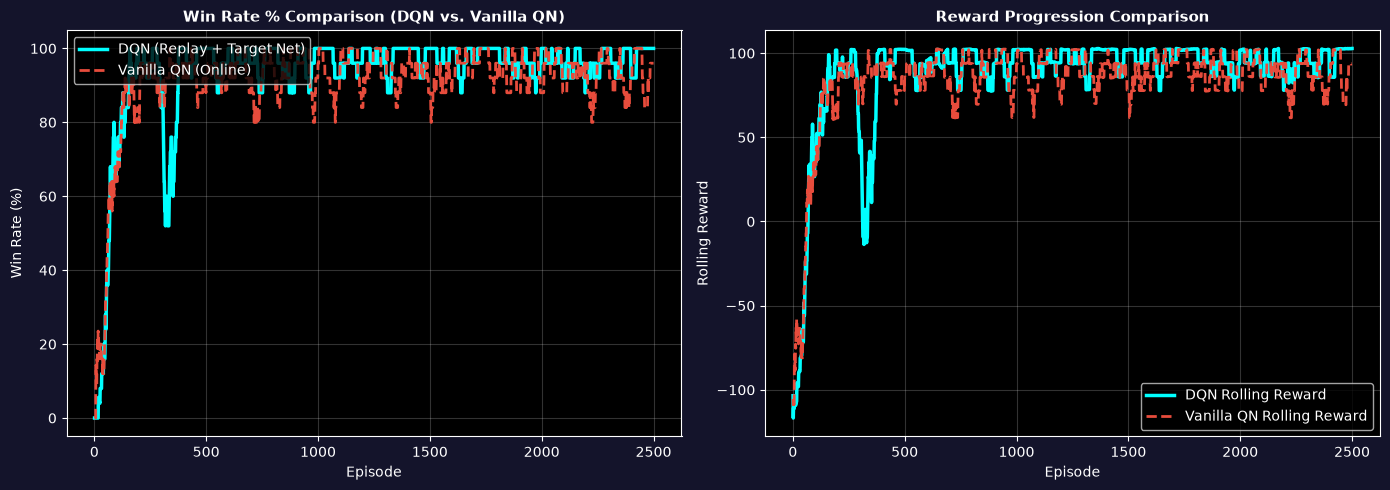

Final DQN Win Rate:        100.0%
Final Vanilla QN Win Rate: 96.0%


In [8]:
# Train Vanilla QN agent on Env 1
qn_agent = VanillaQNAgent(
    grid_size=(train_env.unwrapped.grid_width, train_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.985,
)

qn_metrics = train_qn_agent(
    env=train_env,
    agent=qn_agent,
    num_episodes=NUM_EPISODES,
    verbose_freq=100,
)

# Side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor="#14142B")

ax1.plot(dqn_metrics["episodes"], dqn_metrics["rolling_win_rate"], color="#00FFFF", linewidth=2.5, label="DQN (Replay + Target Net)")
ax1.plot(qn_metrics["episodes"], qn_metrics["rolling_win_rate"], color="#E74C3C", linewidth=2.0, linestyle="--", label="Vanilla QN (Online)")
ax1.set_title("Win Rate % Comparison (DQN vs. Vanilla QN)", fontsize=11, fontweight="bold", color="white")
ax1.set_xlabel("Episode", color="white")
ax1.set_ylabel("Win Rate (%)", color="white")
ax1.set_ylim(-5, 105)
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.2)

ax2.plot(dqn_metrics["episodes"], dqn_metrics["rolling_rewards"], color="#00FFFF", linewidth=2.5, label="DQN Rolling Reward")
ax2.plot(qn_metrics["episodes"], qn_metrics["rolling_rewards"], color="#E74C3C", linewidth=2.0, linestyle="--", label="Vanilla QN Rolling Reward")
ax2.set_title("Reward Progression Comparison", fontsize=11, fontweight="bold", color="white")
ax2.set_xlabel("Episode", color="white")
ax2.set_ylabel("Rolling Reward", color="white")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Final DQN Win Rate:        {dqn_metrics['rolling_win_rate'][-1]:.1f}%")
print(f"Final Vanilla QN Win Rate: {qn_metrics['rolling_win_rate'][-1]:.1f}%")



## 8. Cognitive AI Evaluation: Investigating the Learned Schema

In cognitive reinforcement learning, a **Schema** is an internal mental model of environmental invariants.
We compute the State-Value function:
$$V(s) = \max_{a \in \mathcal{A}} Q(s, a)$$
across every coordinate on the board to visualize the learned potential field directing the agent to the goal.

### Critical Investigation: Why do unrevealed interior tiles show prior values around ~60?
1. **Fog-of-War**: In Minesweeper, tiles are unrevealed until stepped on. From an unrevealed perspective, the network has no perceptual cues indicating where hidden mines lie.
2. **Directional Expectation**: $V(s)$ evaluates the expected return of taking the best action *from* $(r, c)$ towards the goal column. Because reaching the goal gives $+100$ discounted over distance $\gamma^d \approx 60$, the network estimates a positive spatial prior across all unrevealed tiles.
3. **Landmark Overlays**: We overlay `[G]` for the Goal, `[W]` for safe sidewalks, and `[M]` for actual hidden mines, highlighting the contrast between the agent's spatial expectations and ground-truth hazards.



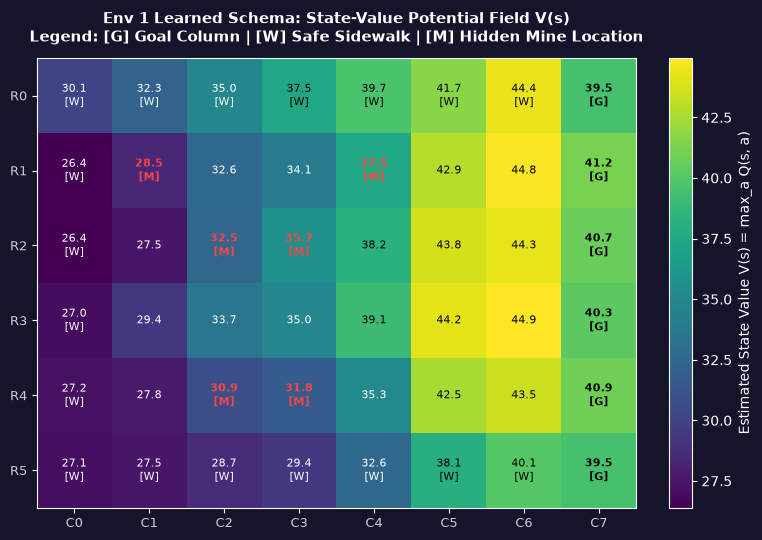

In [9]:
plot_q_value_heatmap(dqn_agent, eval_env, title="Env 1 Learned Schema: State-Value Potential Field V(s)")



## 9. Stability Baseline Across Dynamic Sidewalk Starts

To ensure the forgetting benchmark is not a static 100% flatline, we test the agent across all starting rows along the left sidewalk (`(row 0, col 0)` through `(row 5, col 0)`). This establishes an authentic baseline before fine-tuning in later environments.



Running Catastrophic Forgetting Benchmark (100 episodes on GridNavEnv)...


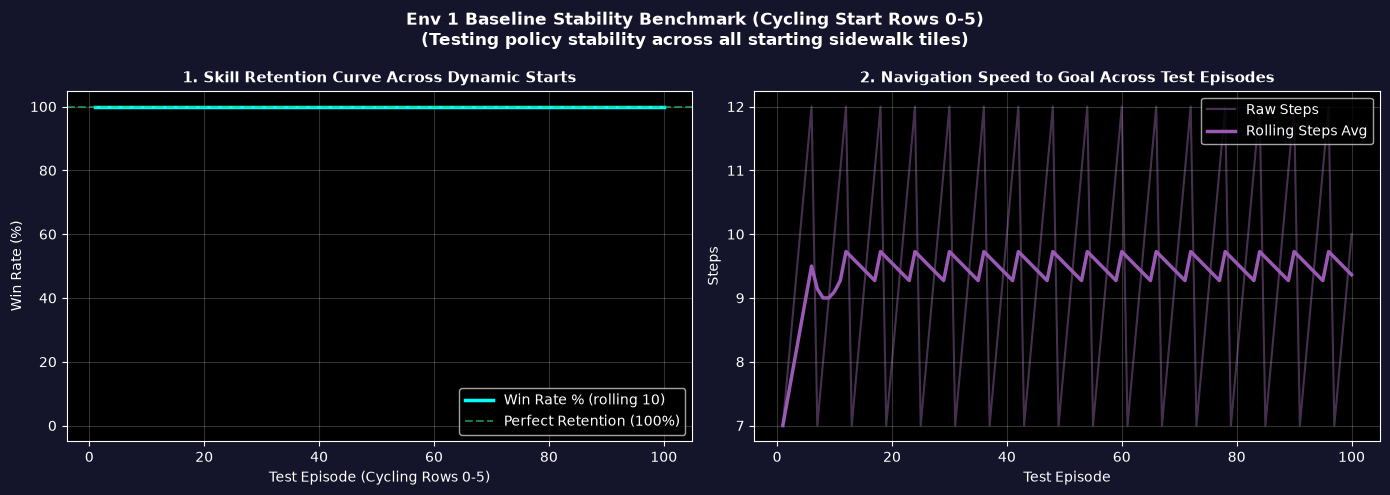

Forgetting Benchmark Summary over 100 episodes:
  Overall Win Rate: 100.0%
  Average Steps:    9.5
  Average Reward:   +103.7
Env 1 Baseline Win Rate across dynamic starts: 100.0%


In [10]:
# Baseline retention test cycling through all starting rows along column 0
baseline_retention = run_forgetting_benchmark(
    agent=dqn_agent,
    test_env=eval_env,
    num_episodes=100,
    title="Env 1 Baseline Stability Benchmark (Cycling Start Rows 0-5)"
)
print(f"Env 1 Baseline Win Rate across dynamic starts: {baseline_retention['mean_win_rate']:.1f}%")

